In [ ]:
from Routines.fq_data_collection import *

from scipy.optimize import brentq
import numpy as np
from datetime import datetime
import time, sys, os, pyvisa, subprocess
import matplotlib as mpl
import matplotlib.pyplot as plt
import time, math

In [3]:
os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\YBCO_probe2_06252026", exist_ok = True)

calib_path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\YBCO_probe2_06252026"

In [ ]:
#wait_for_stable_resistance()

multiRes_fq_characterization(data_save = calib_path, curr_step= 0.02, stop_temp= 45, initial_scan= [3.768, 3.966, 4.262, 4.433, 4.628, 4.856, 5.166, 5.407, 5.592], chan = 2, num_points= 2001, power = -30, set_current = 0.450, reset = False)

c:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Routines\res_to_temp.py:48: RuntimeWarning: divide by zero encountered in log
  log_T = np.log(T)


success!
Channel set to 2

Voltage set to 30
V


TypeError: 'float' object is not callable

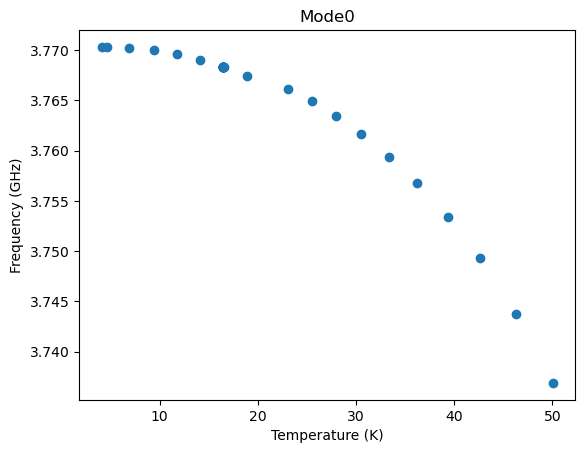

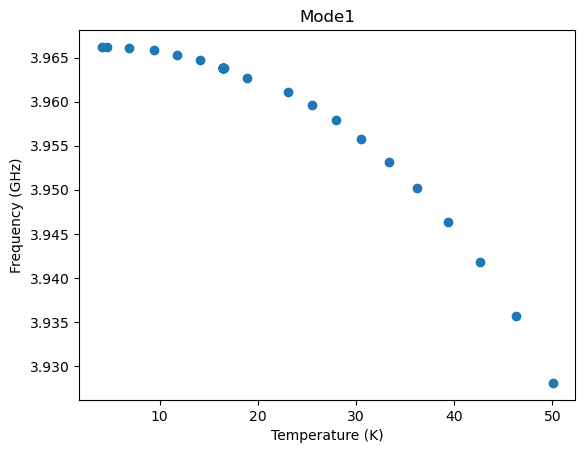

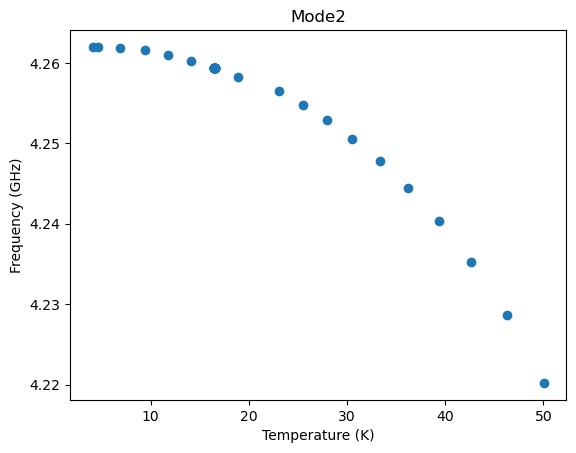

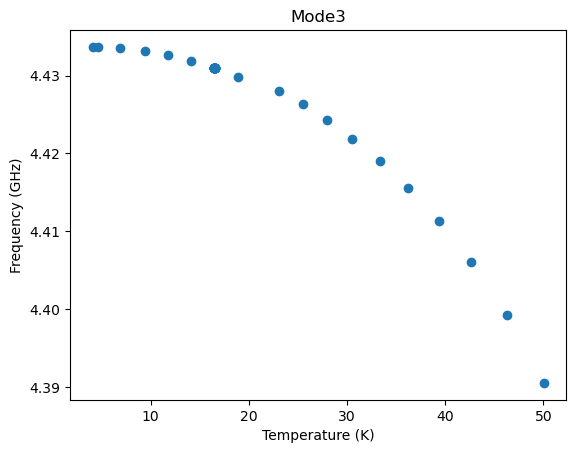

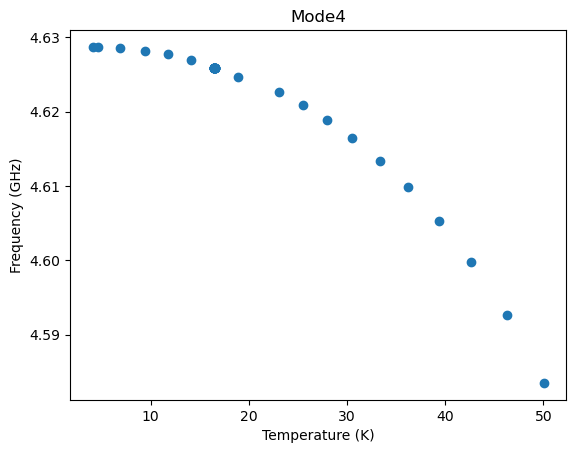

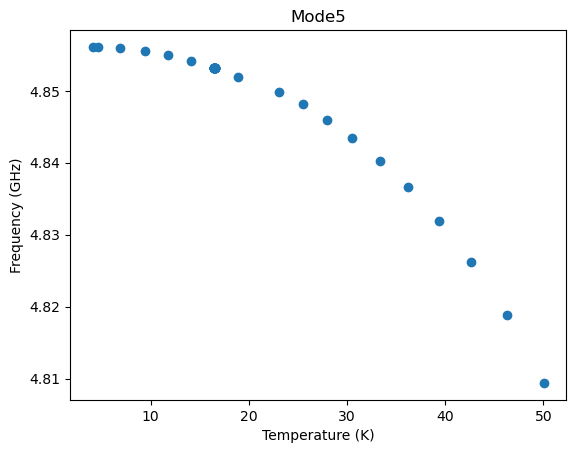

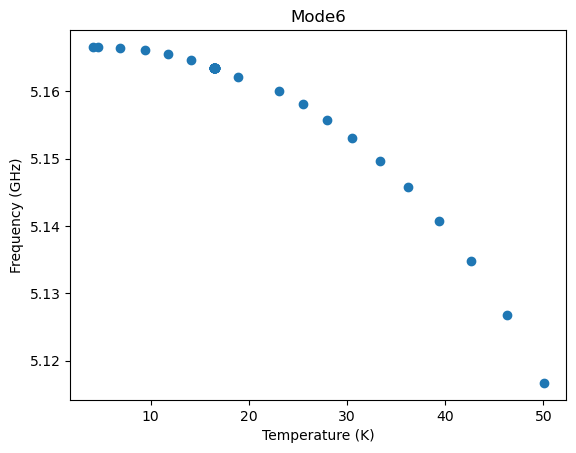

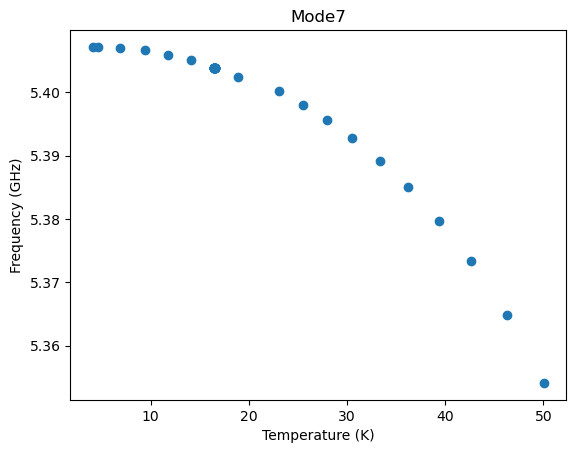

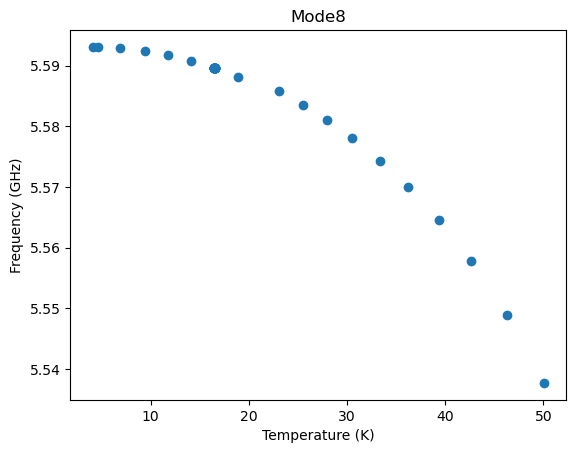

In [9]:
f_dict = {}

T_dict ={}
for mode in range(9):
    f_dict[mode] = []
    T_dict[mode] = []

for i, folder in enumerate(os.listdir(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\calibration_06232026")):
    subfolder = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\calibration_06232026" + '\\' + folder
    for file in os.listdir(subfolder):
        df = pd.read_csv(subfolder + '\\' + file)
        f_data = df.iloc[0, 1:].to_numpy()/1e9
        s_data = df.iloc[1, 1:].to_numpy()

        f_dict[i].append(f_data[np.argmin(s_data)])

        initial_split = (file.split('_')[-3])
        T_val = float(initial_split.split(' ')[0])

        T_dict[i].append(T_val)



for mode,value in f_dict.items():

    plt.scatter(T_dict[mode], value, label = f"mode{mode}")
    plt.xlabel("Temperature (K)")
    plt.ylabel("Frequency (GHz)")
    plt.title(f"Mode{mode}")
    plt.show()

[7.81, 8.4, 9.88, 11.81, 13.97, 16.31, 18.76, 21.27, 23.87, 26.53, 29.22, 32.12, 35.05] [7.81, 8.4, 9.88, 11.81, 13.97, 16.31, 18.76, 21.27, 23.87, 26.53, 29.22, 32.12, 35.05]
